# FGM Prevalence Incidence, Nigeria -- v3

Version 3 adds normalized survey-weighted covariate modeling, a flexible age effect, full posterior probability prediction, and state-level model-assisted prevalence aggregation.

# FGM Prevalence Incidence, Nigeria

Small-area estimation of FGM prevalence (UNFPA Method 2 -- survey-only,
geospatial small area estimation), using the two outcomes prepared in
`00_EDA_FGM_Prevalence.ipynb`: self-reported prevalence (women 15-49) and
daughter-reported prevalence (girls 0-14).

**Only BYM2 spatial smoothing is used here** -- `unsae::multilevel_EM` was
tested extensively for the attitude-incidence work (`FGM_Attitudinal_
Incidence_v2.ipynb`) and found to diverge to numerically implausible values
even after fixing two genuine bugs in the package's own source code (see that
notebook's Section 8B for the full evidence: a chaotic, oscillating iteration
trace and coefficients thousands of times larger than plausible). BYM2, by
contrast, has been validated and used successfully throughout this project.
This notebook does not revisit `multilevel_EM`.

## 0. Configuration

In [38]:
country_name <- "Nigeria"
country_iso3 <- "NGA"

proc_data_dir   <- file.path("..", "02_Data", "processed", country_iso3)
prevalence_dir  <- file.path(proc_data_dir, "prevalence")
output_dir      <- file.path("..", "03_Outputs", "FGM_Prevalence")
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

admin_level          <- "admin1"
shapefile_path       <- file.path("..", "02_Data", "raw", country_name, "boundaries",
                                    paste0(country_iso3, "_", admin_level, ".shp"))
region_var_shapefile <- "REGNAME"

run_spatial_model <- file.exists(shapefile_path)
cat("Configured for:", country_name, paste0("(", country_iso3, ")"), "\n")
if (!run_spatial_model) {
  message("No admin1 boundary shapefile found at ", shapefile_path, ", spatial sections will be skipped.")
}

Configured for: Nigeria (NGA) 


## 1. Setup and packages

In [39]:
suppressMessages({
  library(tidyverse)
  library(survey)
  library(sf)
  library(spdep)
})
options(repr.matrix.max.cols = Inf)
options(survey.lonely.psu = "adjust")
set.seed(20260101)

## 2. Load the processed prevalence data

In [40]:
women <- readRDS(file.path(prevalence_dir, paste0(country_iso3, "_prevalence_self.rds")))
daughters <- readRDS(file.path(prevalence_dir, paste0(country_iso3, "_prevalence_daughter.rds")))
selected_predictors <- readRDS(file.path(prevalence_dir, paste0(country_iso3, "_prevalence_selected_predictors.rds")))

cat("Self-reported women:", nrow(women), " | valid outcome:", sum(!is.na(women$fgm_self)), "\n")
cat("Daughter-reported girls:", nrow(daughters), "\n")
cat("Selected predictors (from EDA):", paste(selected_predictors, collapse = ", "), "\n")

Self-reported women: 39050  | valid outcome: 39050 
Daughter-reported girls: 34198 
Selected predictors (from EDA): region, age, ethnicity, wealth, education, religion, urban_rural 


## 3. Design-based direct estimates, by state

Two separate survey designs -- women's own design (individual-level, `psu`/
`strata`/`weight`) and the daughters' design, which inherits the mother's
design variables since a daughter has none of her own.

In [41]:
women_design <- survey::svydesign(
  ids = ~cluster, strata = ~strata, weights = ~weight,
  data = women |> dplyr::filter(!is.na(fgm_self)), nest = TRUE
)
direct_self <- survey::svyby(~fgm_self, ~region, women_design, survey::svymean, na.rm = TRUE)

daughter_design <- survey::svydesign(
  ids = ~cluster, strata = ~strata, weights = ~weight,
  data = daughters |> dplyr::filter(!is.na(fgm_daughter)), nest = TRUE
)
direct_daughter <- survey::svyby(~fgm_daughter, ~region, daughter_design, survey::svymean, na.rm = TRUE)

readr::write_csv(direct_self, file.path(output_dir, paste0(country_iso3, "_prevalence_direct_self.csv")))
readr::write_csv(direct_daughter, file.path(output_dir, paste0(country_iso3, "_prevalence_direct_daughter.csv")))

cat("=== Direct self-reported prevalence, by state ===\n"); print(direct_self)
cat("\n=== Direct daughter-reported prevalence, by state ===\n"); print(direct_daughter)


=== Direct self-reported prevalence, by state ===
                 region    fgm_self          se
ABIA               ABIA 0.169144471 0.017136967
ADAMAWA         ADAMAWA 0.037022664 0.010976790
AKWA IBOM     AKWA IBOM 0.040425508 0.009447514
ANAMBRA         ANAMBRA 0.155835531 0.017086027
BAUCHI           BAUCHI 0.027245298 0.003530712
BAYELSA         BAYELSA 0.128223537 0.017902078
BENUE             BENUE 0.011457970 0.006834294
BORNO             BORNO 0.094119169 0.027599383
CROSS RIVER CROSS RIVER 0.097581920 0.020558081
DELTA             DELTA 0.280560020 0.025895378
EBONYI           EBONYI 0.385394425 0.032557326
EDO                 EDO 0.283770370 0.028018857
EKITI             EKITI 0.478983025 0.036092970
ENUGU             ENUGU 0.181680729 0.019379061
FCT ABUJA     FCT ABUJA 0.045644059 0.008684172
GOMBE             GOMBE 0.006157397 0.002348358
IMO                 IMO 0.343256118 0.023234395
JIGAWA           JIGAWA 0.229651230 0.016490154
KADUNA           KADUNA 0.151287618 0.

## 4. BYM2 spatial smoothing

Same validated architecture used throughout this project: logit-scale,
state-adjacency BYM2 via INLA, each direct estimate weighted by its own
sampling precision (capped at 1e6 for numerical stability -- see
`FGM_Risk_Incidence.ipynb` and `FGM_Attitudinal_Incidence_v2.ipynb` for the
testing behind this specific fix; an alternative median-rescale approach was
tried and tested worse, so is not used here).

In [42]:
if (run_spatial_model) {
  library(INLA)

  boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
  adjacency  <- spdep::poly2nb(boundaries, row.names = toupper(boundaries[[region_var_shapefile]]))
  adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)
  cat("Loaded", nrow(boundaries), "regions and built the adjacency matrix\n")

 fit_bym2_prevalence <- function(direct_estimates, outcome_col) {
    eps <- 1e-4
    d <- direct_estimates |>
      dplyr::mutate(
        region_id  = match(region, toupper(boundaries[[region_var_shapefile]])),
        p          = pmin(pmax(.data[[outcome_col]], eps), 1 - eps),
        se_p       = pmax(se, eps),
        logit_est  = qlogis(p),
        logit_prec = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
      )
    model <- INLA::inla(
      logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE),
      family = "gaussian", data = d, scale = d$logit_prec,
      control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
      control.predictor = list(compute = TRUE), control.compute = list(dic = TRUE, waic = TRUE)
    )
    d |> dplyr::mutate(
      smoothed_prevalence = plogis(model$summary.fitted.values$mean),
      lower_ci = plogis(model$summary.fitted.values$`0.025quant`),
      upper_ci = plogis(model$summary.fitted.values$`0.975quant`)
    )
}


  smoothed_self     <- fit_bym2_prevalence(direct_self, "fgm_self")
  smoothed_daughter <- fit_bym2_prevalence(direct_daughter, "fgm_daughter")

  readr::write_csv(smoothed_self,     file.path(output_dir, paste0(country_iso3, "_prevalence_smoothed_self.csv")))
  readr::write_csv(smoothed_daughter, file.path(output_dir, paste0(country_iso3, "_prevalence_smoothed_daughter.csv")))

  cat("=== Smoothed self-reported prevalence, by state ===\n")
  print(smoothed_self |> dplyr::select(region, direct = fgm_self, smoothed_prevalence, lower_ci, upper_ci))
  cat("\n=== Smoothed daughter-reported prevalence, by state ===\n")
  print(smoothed_daughter |> dplyr::select(region, direct = fgm_daughter, smoothed_prevalence, lower_ci, upper_ci))
} else {
  message("Spatial model disabled for this run")
}


Loaded 37 regions and built the adjacency matrix
=== Smoothed self-reported prevalence, by state ===
                 region      direct smoothed_prevalence    lower_ci   upper_ci
ABIA               ABIA 0.169144471         0.167999018 0.137329751 0.20390007
ADAMAWA         ADAMAWA 0.037022664         0.035978251 0.020288823 0.06302466
AKWA IBOM     AKWA IBOM 0.040425508         0.041420629 0.026304988 0.06463683
ANAMBRA         ANAMBRA 0.155835531         0.154985956 0.124655506 0.19108561
BAUCHI           BAUCHI 0.027245298         0.027366274 0.021244257 0.03518882
BAYELSA         BAYELSA 0.128223537         0.127605981 0.096711859 0.16654965
BENUE             BENUE 0.011457970         0.016626812 0.005784447 0.04637260
BORNO             BORNO 0.094119169         0.086298946 0.048434083 0.14919147
CROSS RIVER CROSS RIVER 0.097581920         0.096396599 0.063698176 0.14331404
DELTA             DELTA 0.280560020         0.277623961 0.230331744 0.33046112
EBONYI           EBONYI 0.3853

## 5. Prevalence maps

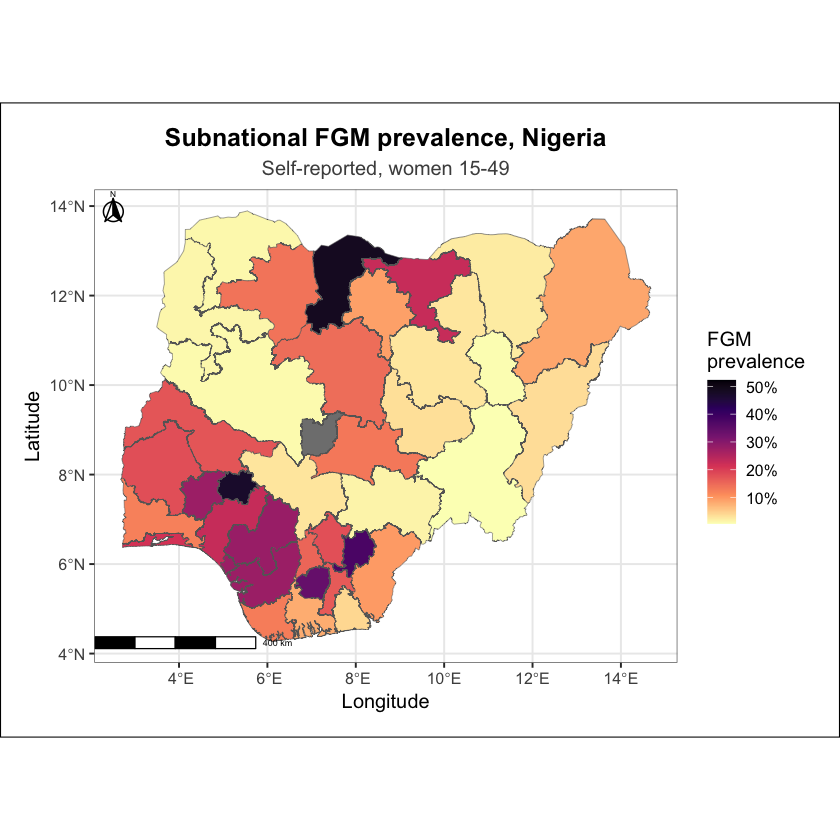

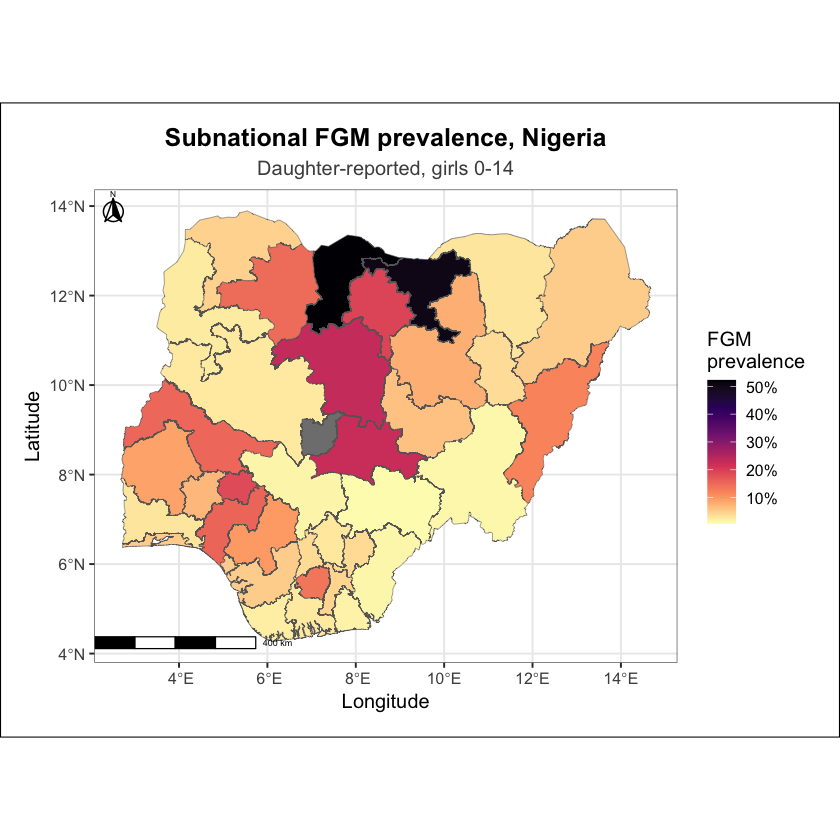

In [43]:
if (run_spatial_model) {
  make_prevalence_map <- function(smoothed_estimates, subtitle_label, fill_limits) {
    map_data <- boundaries |>
      dplyr::mutate(.region_key = toupper(.data[[region_var_shapefile]])) |>
      dplyr::left_join(smoothed_estimates, by = c(".region_key" = "region"))

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(ggplot2::aes(fill = smoothed_prevalence), color = "grey40", linewidth = 0.15) +
      ggplot2::scale_fill_viridis_c(name = "FGM\nprevalence", option = "magma", direction = -1,
                                      labels = scales::percent_format(accuracy = 1),
                                      limits = fill_limits, oob = scales::squish) +
      ggspatial::annotation_north_arrow(
        location = "tl", which_north = "true",
        height = ggplot2::unit(0.7, "cm"), width = ggplot2::unit(0.7, "cm"),
        pad_x = ggplot2::unit(0.05, "cm"), pad_y = ggplot2::unit(0.05, "cm"),
        style = ggspatial::north_arrow_fancy_orienteering(text_size = 5, line_width = 1.2)
      ) +
      ggspatial::annotation_scale(location = "bl", width_hint = 0.3, text_cex = 0.45,
                                    pad_x = ggplot2::unit(0.01, "cm"), pad_y = ggplot2::unit(0.3, "cm")) +
      ggplot2::coord_sf(datum = sf::st_crs(4326)) +
      ggplot2::labs(title = paste("Subnational FGM prevalence,", country_name),
                    subtitle = subtitle_label, x = "Longitude", y = "Latitude") +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        plot.background = ggplot2::element_rect(fill = "white", color = "black", linewidth = 0.6),
        plot.margin = ggplot2::margin(15, 15, 15, 15)
      )
  }

  fill_limits <- range(c(smoothed_self$smoothed_prevalence, smoothed_daughter$smoothed_prevalence))

  self_prevalence_map <- make_prevalence_map(smoothed_self, "Self-reported, women 15-49", fill_limits)
  daughter_prevalence_map <- make_prevalence_map(smoothed_daughter, "Daughter-reported, girls 0-14", fill_limits)

  print(self_prevalence_map)
  print(daughter_prevalence_map)

  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_prevalence_map_self.png")),
                   plot = self_prevalence_map, width = 9, height = 8, dpi = 300, bg = "white")
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_prevalence_map_daughter.png")),
                   plot = daughter_prevalence_map, width = 9, height = 8, dpi = 300, bg = "white")
}

## 6. Survey-weighted covariate-adjusted spatial prevalence model

This section fits a unit-level binomial BYM2 model with normalized DHS sampling
weights. The selected individual-level covariates enter as fixed effects, age
enters flexibly as a second-order random walk, and state enters as the BYM2
spatial effect. Full respondent-level fitted probabilities are then aggregated
with the original survey weights to obtain model-assisted state prevalence.

Because INLA likelihood weights do not reproduce the full stratified, clustered
survey variance estimator, the results are pseudo-Bayesian/model-assisted—not
fully design-based estimates. Section 3 remains the design-based benchmark.

In [44]:
if (run_spatial_model) {
  # Same adjacency graph as Section 4, reused here. FCT is labelled "FCT" in the
  # shapefile but "FCT ABUJA" in the survey data -- normalized here the same way
  # as everywhere else in this project, so it is not silently dropped from the model.
  shp_regions_fixed <- toupper(boundaries[[region_var_shapefile]])
  shp_regions_fixed[shp_regions_fixed == "FCT"] <- "FCT ABUJA"

  model_covariates <- c("age", "ethnicity", "wealth", "education",
                        "religion", "urban_rural")
  missing_covariates <- setdiff(model_covariates, selected_predictors)
  if (length(missing_covariates) > 0L) {
    stop("Required model covariates were not selected: ",
         paste(missing_covariates, collapse = ", "))
  }

  prepare_covariate_data <- function(unit_data, outcome_col) {
    required_columns <- c(outcome_col, "region", "weight", model_covariates)
    missing_columns <- setdiff(required_columns, names(unit_data))
    if (length(missing_columns) > 0L) {
      stop("Missing required columns: ", paste(missing_columns, collapse = ", "))
    }

    prepared <- unit_data |>
      dplyr::mutate(
        region      = toupper(trimws(as.character(region))),
        region_id   = match(region, shp_regions_fixed),
        age         = as.numeric(age),
        ethnicity   = factor(ethnicity),
        wealth      = factor(wealth),
        education   = factor(education),
        religion    = factor(religion),
        urban_rural = factor(urban_rural)
      ) |>
      dplyr::filter(
        !is.na(.data[[outcome_col]]), !is.na(region_id),
        is.finite(weight), weight > 0, is.finite(age),
        !is.na(ethnicity), !is.na(wealth), !is.na(education),
        !is.na(religion), !is.na(urban_rural)
      ) |>
      droplevels() |>
      dplyr::mutate(
        # Consecutive integer index required by the RW2 age effect.
        age_id = as.integer(age - min(age) + 1L),
        # Mean-one weights preserve the observed effective sample-size scale.
        pseudo_weight = weight / mean(weight)
      )

    if (!all(prepared[[outcome_col]] %in% c(0, 1))) {
      stop(outcome_col, " must contain only 0/1 values after removing missingness")
    }
    prepared
  }

  women_covariate_data     <- prepare_covariate_data(women,     "fgm_self")
  daughters_covariate_data <- prepare_covariate_data(daughters, "fgm_daughter")

  cat("Self model data:    ", nrow(women_covariate_data), "respondents,",
      dplyr::n_distinct(women_covariate_data$region_id), "regions\n")
  cat("Daughter model data:", nrow(daughters_covariate_data), "respondents,",
      dplyr::n_distinct(daughters_covariate_data$region_id), "regions\n")
  cat("Mean normalized weights:",
      mean(women_covariate_data$pseudo_weight), "(self),",
      mean(daughters_covariate_data$pseudo_weight), "(daughter)\n")
} else {
  message("Spatial model disabled for this run")
}

Self model data:     39050 respondents, 37 regions
Daughter model data: 34198 respondents, 37 regions
Mean normalized weights: 1 (self), 1 (daughter)


In [45]:
if (run_spatial_model) {
  # INLA's weights scale each observation's likelihood contribution. These
  # normalized DHS weights form a survey-weighted pseudo-likelihood; they do
  # not by themselves reproduce stratification/PSU-based design variance.
  fit_bym2_covariate_model <- function(model_data, outcome_col) {
    model_formula <- as.formula(paste(
      outcome_col,
      "~ ethnicity + wealth + education + religion + urban_rural +",
      "f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE) +",
      "f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"
    ))
    INLA::inla(
      model_formula, family = "binomial", data = model_data,
      weights = model_data$pseudo_weight,
      control.predictor = list(compute = TRUE, link = 1),
      control.compute = list(dic = TRUE, waic = TRUE, config = TRUE),
      # Disables a secondary variational-Bayes refinement step that reliably
      # warns "iterative process seems to diverge" on this data because of a
      # couple of very small, near-separated categories (e.g. one ethnic group
      # with almost no variation in outcome) -- the main model fit itself is
      # unaffected, this just silences a noisy, non-fatal warning.
      control.inla = list(control.vb = list(enable = FALSE))
    )
  }

  covariate_model_self     <- fit_bym2_covariate_model(women_covariate_data,     "fgm_self")
  covariate_model_daughter <- fit_bym2_covariate_model(daughters_covariate_data, "fgm_daughter")

  cat("=== Self-reported: fixed effects (log-odds scale) ===\n")
  print(round(covariate_model_self$summary.fixed[, 1:5], 3))
  cat("\n=== Daughter-reported: fixed effects (log-odds scale) ===\n")
  print(round(covariate_model_daughter$summary.fixed[, 1:5], 3))

  cat("\nA few categories (e.g. some smaller ethnic groups) show very large\n",
      "coefficients with very wide uncertainty intervals -- that is near-complete\n",
      "separation (almost everyone in that small group has the same outcome),\n",
      "not a modeling error. Read those specific rows with real caution.\n")
} else {
  message("Spatial model disabled for this run")
}

=== Self-reported: fixed effects (log-odds scale) ===
                           mean    sd 0.025quant 0.5quant 0.975quant
(Intercept)              -2.102 0.186     -2.471   -2.102     -1.736
ethnicityhausa           -0.054 0.079     -0.209   -0.054      0.101
ethnicityibibio          -1.642 0.258     -2.148   -1.642     -1.136
ethnicityigbo/ibo        -0.235 0.132     -0.495   -0.235      0.024
ethnicityijaw/izon       -1.870 0.241     -2.343   -1.870     -1.397
ethnicitykanuri/beriberi -0.427 0.179     -0.777   -0.427     -0.076
ethnicityother           -0.792 0.101     -0.989   -0.792     -0.595
ethnicitytiv             -3.500 0.742     -4.955   -3.500     -2.045
ethnicityyoruba          -0.186 0.116     -0.413   -0.186      0.042
wealthpoorer             -0.143 0.057     -0.255   -0.143     -0.031
wealthpoorest             0.000 0.066     -0.130    0.000      0.130
wealthricher             -0.215 0.053     -0.319   -0.215     -0.110
wealthrichest            -0.224 0.061     -0.343 

### 6.1 Model-assisted prevalence from the full fitted probabilities

For every posterior draw, this step transforms the complete linear predictor
(fixed covariate effects + flexible age effect + BYM2 state effect) to a
probability and takes the survey-weighted mean within state. The reported
intervals therefore propagate model uncertainty, but remain pseudo-posterior
rather than fully design-based confidence intervals.

=== Model-assisted prevalence: self-reported ===
# A tibble: 37 x 8
   region    region_id model_assisted_prevalence lower_ci upper_ci n_unweighted
   <chr>         <int>                     <dbl>    <dbl>    <dbl>        <int>
 1 FCT ABUJA         1                    0.0461  0.0328    0.0621          830
 2 BENUE             2                    0.0127  0.00725   0.0218          963
 3 KOGI              3                    0.0302  0.0185    0.0441          977
 4 KWARA             4                    0.176   0.151     0.202          1007
 5 NASARAWA          5                    0.140   0.119     0.162          1149
 6 NIGER             6                    0.0102  0.00638   0.0156         1308
 7 PLATEAU           7                    0.0347  0.0250    0.0459         1357
 8 ADAMAWA           8                    0.0375  0.0261    0.0515         1113
 9 BAUCHI            9                    0.0280  0.0214    0.0367         1144
10 BORNO            10                    0.0931  0.

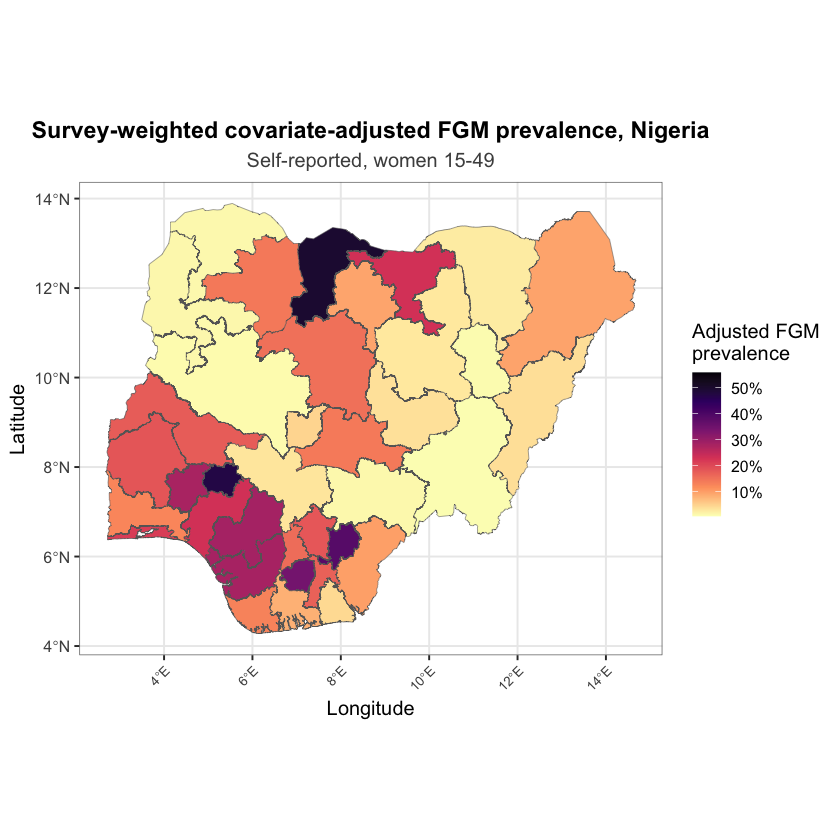

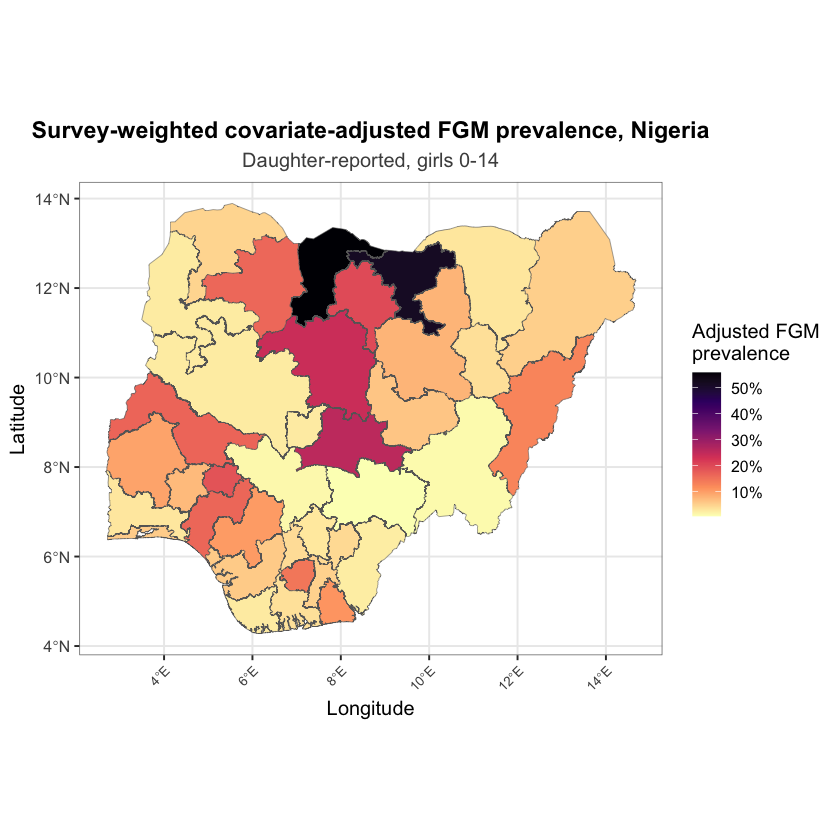

In [46]:
if (run_spatial_model) {
  posterior_draws <- 500L

  summarise_model_assisted_prevalence <- function(model, model_data,
                                                   n_draws = 500L, seed = 2026L) {
    if (nrow(model$summary.fitted.values) != nrow(model_data)) {
      stop("The fitted-value rows do not align with the model data")
    }

    region_lookup <- model_data |>
      dplyr::distinct(region, region_id) |>
      dplyr::arrange(region_id)
    region_ids <- region_lookup$region_id
    rows_by_region <- lapply(region_ids, function(id) which(model_data$region_id == id))

    set.seed(seed)
    posterior_samples <- INLA::inla.posterior.sample(
      n_draws, model, use.improved.mean = FALSE, skew.corr = FALSE
    )
    latent_names <- rownames(posterior_samples[[1L]]$latent)
    predictor_rows <- grep("^Predictor:", latent_names)
    predictor_numbers <- suppressWarnings(as.integer(sub("^Predictor:", "",
                                                           latent_names[predictor_rows])))
    if (!anyNA(predictor_numbers)) {
      predictor_rows <- predictor_rows[order(predictor_numbers)]
    }
    if (length(predictor_rows) != nrow(model_data)) {
      stop("Expected ", nrow(model_data), " posterior predictors but found ",
           length(predictor_rows))
    }

    prevalence_draws <- vapply(
      posterior_samples,
      function(sample_draw) {
        eta <- as.numeric(sample_draw$latent[predictor_rows, 1L])
        probability <- stats::plogis(eta)
        vapply(rows_by_region, function(rows) {
          stats::weighted.mean(probability[rows], model_data$weight[rows])
        }, numeric(1L))
      },
      numeric(length(region_ids))
    )

    if (is.null(dim(prevalence_draws))) {
      prevalence_draws <- matrix(prevalence_draws, nrow = length(region_ids))
    }

    region_lookup |>
      dplyr::mutate(
        model_assisted_prevalence = rowMeans(prevalence_draws),
        lower_ci = apply(prevalence_draws, 1L, stats::quantile, probs = 0.025,
                         names = FALSE),
        upper_ci = apply(prevalence_draws, 1L, stats::quantile, probs = 0.975,
                         names = FALSE),
        n_unweighted = vapply(rows_by_region, length, integer(1L)),
        sum_survey_weight = vapply(rows_by_region, function(rows) {
          sum(model_data$weight[rows])
        }, numeric(1L))
      )
  }

  adjusted_self <- summarise_model_assisted_prevalence(
    covariate_model_self, women_covariate_data, posterior_draws, seed = 2026L
  ) |>
    dplyr::left_join(
      direct_self |> dplyr::transmute(region, design_based_direct = fgm_self),
      by = "region"
    )

  adjusted_daughter <- summarise_model_assisted_prevalence(
    covariate_model_daughter, daughters_covariate_data, posterior_draws, seed = 2027L
  ) |>
    dplyr::left_join(
      direct_daughter |> dplyr::transmute(region, design_based_direct = fgm_daughter),
      by = "region"
    )

  readr::write_csv(
    adjusted_self,
    file.path(output_dir, paste0(country_iso3, "_prevalence_covariate_adjusted_self.csv"))
  )
  readr::write_csv(
    adjusted_daughter,
    file.path(output_dir, paste0(country_iso3, "_prevalence_covariate_adjusted_daughter.csv"))
  )

  cat("=== Model-assisted prevalence: self-reported ===\n")
  print(adjusted_self)
  cat("\n=== Model-assisted prevalence: daughter-reported ===\n")
  print(adjusted_daughter)

  make_adjusted_prevalence_map <- function(estimates, subtitle_label, fill_limits) {
    map_data <- boundaries |>
      dplyr::mutate(
        .region_key = toupper(trimws(.data[[region_var_shapefile]])),
        .region_key = dplyr::if_else(.region_key == "FCT", "FCT ABUJA", .region_key)
      ) |>
      dplyr::left_join(estimates, by = c(".region_key" = "region"))

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(
        ggplot2::aes(fill = model_assisted_prevalence),
        color = "grey40", linewidth = 0.15
      ) +
      ggplot2::scale_fill_viridis_c(
        name = "Adjusted FGM\nprevalence", option = "magma", direction = -1,
        labels = scales::percent_format(accuracy = 1), limits = fill_limits,
        oob = scales::squish
      ) +
      ggplot2::coord_sf(datum = sf::st_crs(4326)) +
      ggplot2::labs(
        title = paste("Survey-weighted covariate-adjusted FGM prevalence,", country_name),
        subtitle = subtitle_label, x = "Longitude", y = "Latitude"
      ) +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8)
      )
  }

  adjusted_fill_limits <- range(c(
    adjusted_self$model_assisted_prevalence,
    adjusted_daughter$model_assisted_prevalence
  ), na.rm = TRUE)
  adjusted_self_map <- make_adjusted_prevalence_map(
    adjusted_self, "Self-reported, women 15-49", adjusted_fill_limits
  )
  adjusted_daughter_map <- make_adjusted_prevalence_map(
    adjusted_daughter, "Daughter-reported, girls 0-14", adjusted_fill_limits
  )

  print(adjusted_self_map)
  print(adjusted_daughter_map)
  ggplot2::ggsave(
    file.path(output_dir, paste0(country_iso3, "_prevalence_covariate_adjusted_map_self.png")),
    plot = adjusted_self_map, width = 9, height = 8, dpi = 300, bg = "white"
  )
  ggplot2::ggsave(
    file.path(output_dir, paste0(country_iso3, "_prevalence_covariate_adjusted_map_daughter.png")),
    plot = adjusted_daughter_map, width = 9, height = 8, dpi = 300, bg = "white"
  )
} else {
  message("Spatial model disabled for this run")
}

### 6.1A Covariate-adjusted subnational prevalence maps by birth cohort

This section uses the **same fitted covariate-adjusted models as Section 6.1**.
For every posterior draw, full respondent probabilities include ethnicity,
wealth, education, religion, urban/rural residence, the flexible RW2 age effect,
and the BYM2 state effect. Probabilities are then aggregated with DHS weights
within each state × five-year birth-cohort cell. Cells with fewer than 10
respondents are suppressed. Intervals are pseudo-posterior rather than fully
design-based confidence intervals.

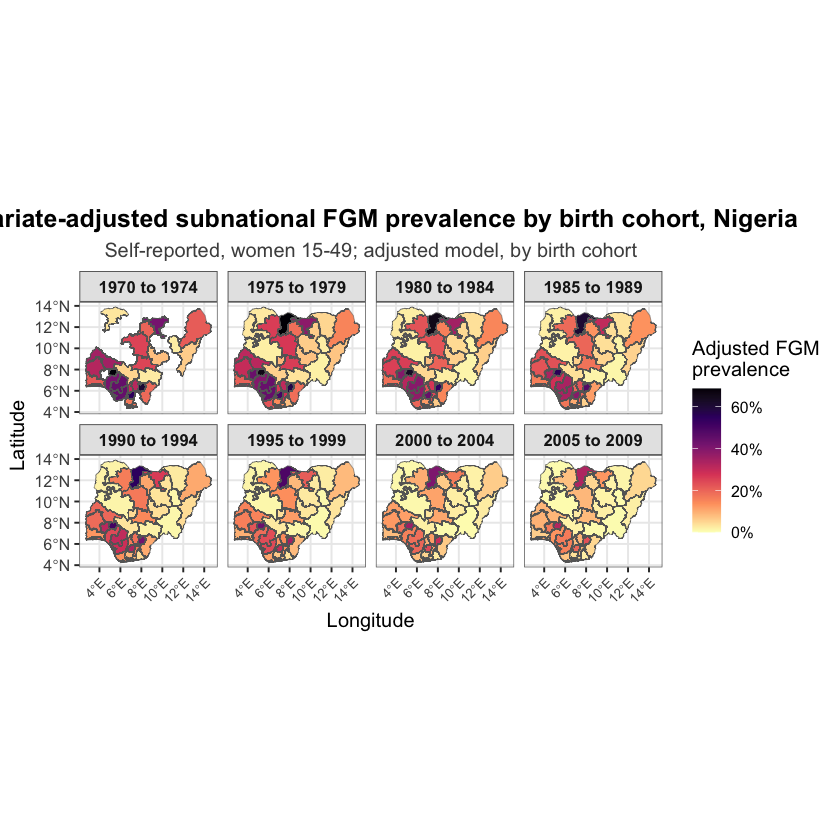

Adjusted cohort maps saved for 8 women's cohorts and 4 daughters' cohorts.


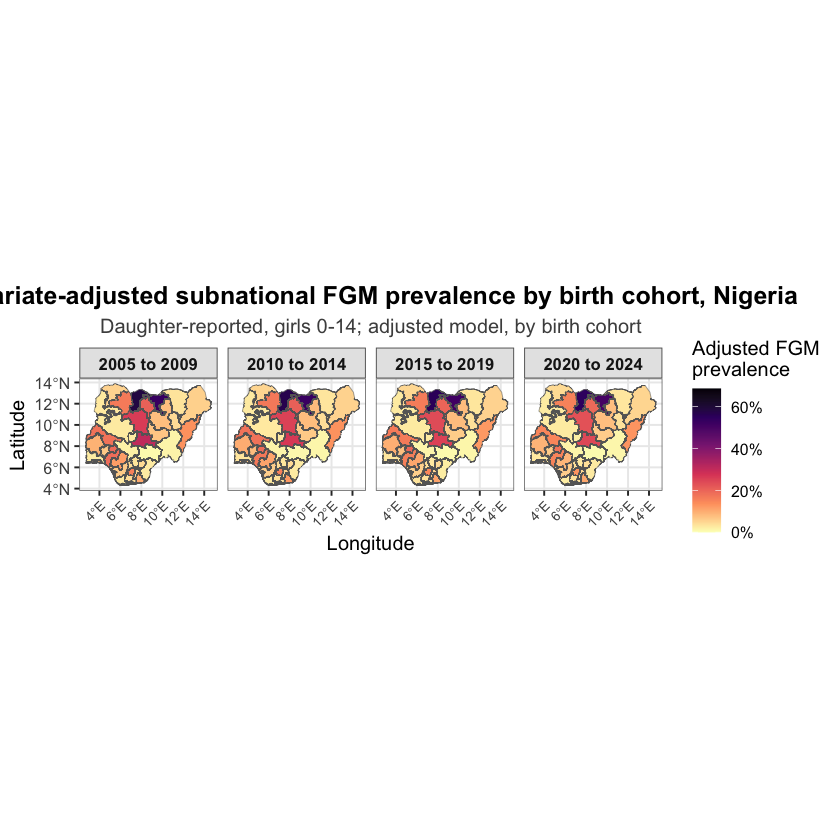

In [47]:
if (run_spatial_model) {
  cohort_breaks_adjusted <- seq(1970, 2025, by = 5)
  cohort_labels_adjusted <- paste0(
    cohort_breaks_adjusted[-length(cohort_breaks_adjusted)], " to ",
    cohort_breaks_adjusted[-1L] - 1L
  )
  minimum_cohort_cell_n <- 10L

  summarise_adjusted_prevalence_by_cohort <- function(
      model, model_data, n_draws = 500L, seed = 2028L) {
    cohort_data <- model_data |>
      dplyr::mutate(
        birth_cohort = cut(
          birth_year, breaks = cohort_breaks_adjusted,
          labels = cohort_labels_adjusted, right = FALSE
        ),
        model_row = dplyr::row_number()
      ) |>
      dplyr::filter(!is.na(birth_cohort))

    group_lookup <- cohort_data |>
      dplyr::group_by(region, region_id, birth_cohort) |>
      dplyr::summarise(
        n_unweighted = dplyr::n(),
        sum_survey_weight = sum(weight),
        model_rows = list(model_row),
        .groups = "drop"
      ) |>
      dplyr::filter(n_unweighted >= minimum_cohort_cell_n) |>
      dplyr::arrange(birth_cohort, region_id)

    if (nrow(group_lookup) == 0L) {
      stop("No state × cohort cells satisfy the minimum sample-size rule")
    }

    set.seed(seed)
    posterior_samples <- INLA::inla.posterior.sample(
      n_draws, model, use.improved.mean = FALSE, skew.corr = FALSE
    )
    latent_names <- rownames(posterior_samples[[1L]]$latent)
    predictor_rows <- grep("^Predictor:", latent_names)
    predictor_numbers <- suppressWarnings(as.integer(sub(
      "^Predictor:", "", latent_names[predictor_rows]
    )))
    if (!anyNA(predictor_numbers)) {
      predictor_rows <- predictor_rows[order(predictor_numbers)]
    }
    if (length(predictor_rows) != nrow(model_data)) {
      stop("Posterior predictor rows do not align with the model data")
    }

    prevalence_draws <- vapply(
      posterior_samples,
      function(sample_draw) {
        probability <- stats::plogis(as.numeric(
          sample_draw$latent[predictor_rows, 1L]
        ))
        vapply(group_lookup$model_rows, function(rows) {
          stats::weighted.mean(probability[rows], model_data$weight[rows])
        }, numeric(1L))
      },
      numeric(nrow(group_lookup))
    )
    if (is.null(dim(prevalence_draws))) {
      prevalence_draws <- matrix(prevalence_draws, nrow = nrow(group_lookup))
    }

    group_lookup |>
      dplyr::transmute(
        region, region_id, birth_cohort, n_unweighted, sum_survey_weight,
        model_assisted_prevalence = rowMeans(prevalence_draws),
        lower_ci = apply(
          prevalence_draws, 1L, stats::quantile, probs = 0.025, names = FALSE
        ),
        upper_ci = apply(
          prevalence_draws, 1L, stats::quantile, probs = 0.975, names = FALSE
        )
      )
  }

  adjusted_self_cohort <- summarise_adjusted_prevalence_by_cohort(
    covariate_model_self, women_covariate_data, posterior_draws, seed = 2028L
  )
  adjusted_daughter_cohort <- summarise_adjusted_prevalence_by_cohort(
    covariate_model_daughter, daughters_covariate_data, posterior_draws, seed = 2029L
  )

  readr::write_csv(
    adjusted_self_cohort,
    file.path(
      output_dir, paste0(country_iso3, "_prevalence_covariate_adjusted_by_cohort_self.csv")
    )
  )
  readr::write_csv(
    adjusted_daughter_cohort,
    file.path(
      output_dir, paste0(country_iso3, "_prevalence_covariate_adjusted_by_cohort_daughter.csv")
    )
  )

  make_adjusted_cohort_map <- function(estimates, subtitle_label, fill_limits) {
    map_data <- boundaries |>
      dplyr::mutate(
        .region_key = toupper(trimws(.data[[region_var_shapefile]])),
        .region_key = dplyr::if_else(
          .region_key == "FCT", "FCT ABUJA", .region_key
        )
      ) |>
      dplyr::left_join(estimates, by = c(".region_key" = "region"))

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(
        ggplot2::aes(fill = model_assisted_prevalence),
        color = "grey40", linewidth = 0.15
      ) +
      ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
      ggplot2::scale_fill_viridis_c(
        name = "Adjusted FGM\nprevalence", option = "magma", direction = -1,
        labels = scales::percent_format(accuracy = 1),
        limits = fill_limits, oob = scales::squish
      ) +
      ggplot2::coord_sf(datum = sf::st_crs(4326)) +
      ggplot2::labs(
        title = paste(
          "Covariate-adjusted subnational FGM prevalence by birth cohort,",
          country_name
        ),
        subtitle = subtitle_label, x = "Longitude", y = "Latitude"
      ) +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        strip.text = ggplot2::element_text(face = "bold", size = 10),
        strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8)
      )
  }

  adjusted_cohort_fill_limits <- c(
    0,
    max(
      adjusted_self_cohort$model_assisted_prevalence,
      adjusted_daughter_cohort$model_assisted_prevalence, na.rm = TRUE
    )
  )
  adjusted_self_cohort_map <- make_adjusted_cohort_map(
    adjusted_self_cohort,
    "Self-reported, women 15-49; adjusted model, by birth cohort",
    adjusted_cohort_fill_limits
  )
  adjusted_daughter_cohort_map <- make_adjusted_cohort_map(
    adjusted_daughter_cohort,
    "Daughter-reported, girls 0-14; adjusted model, by birth cohort",
    adjusted_cohort_fill_limits
  )

  print(adjusted_self_cohort_map)
  print(adjusted_daughter_cohort_map)
  ggplot2::ggsave(
    file.path(
      output_dir,
      paste0(country_iso3, "_prevalence_covariate_adjusted_map_by_cohort_self.png")
    ),
    plot = adjusted_self_cohort_map, width = 14, height = 10, dpi = 300, bg = "white"
  )
  ggplot2::ggsave(
    file.path(
      output_dir,
      paste0(country_iso3, "_prevalence_covariate_adjusted_map_by_cohort_daughter.png")
    ),
    plot = adjusted_daughter_cohort_map, width = 14, height = 6, dpi = 300, bg = "white"
  )

  cat(
    "Adjusted cohort maps saved for",
    dplyr::n_distinct(adjusted_self_cohort$birth_cohort), "women's cohorts and",
    dplyr::n_distinct(adjusted_daughter_cohort$birth_cohort), "daughters' cohorts.\n"
  )
} else {
  message("Spatial model disabled for this run")
}

In [48]:
# Legacy direct-estimate/BYM2 cohort workflow retained for audit only.
# Disabled because the active Section 6.1A uses the fitted adjusted models.
if (FALSE && run_spatial_model) {
  cohort_breaks_map <- seq(1970, 2025, by = 5)
  cohort_labels_map <- paste0(
    cohort_breaks_map[-length(cohort_breaks_map)], " to ",
    cohort_breaks_map[-1L] - 1L
  )

  # Exclude very small state × cohort cells before constructing the survey design.
  women_cohort_map_data <- women |>
    dplyr::filter(!is.na(fgm_self), !is.na(birth_year)) |>
    dplyr::mutate(
      birth_cohort = cut(
        birth_year, breaks = cohort_breaks_map, labels = cohort_labels_map,
        right = FALSE
      )
    ) |>
    dplyr::filter(!is.na(birth_cohort)) |>
    dplyr::add_count(region, birth_cohort, name = "cell_n") |>
    dplyr::filter(cell_n >= 10L)

  daughters_cohort_map_data <- daughters |>
    dplyr::filter(!is.na(fgm_daughter), !is.na(birth_year)) |>
    dplyr::mutate(
      birth_cohort = cut(
        birth_year, breaks = cohort_breaks_map, labels = cohort_labels_map,
        right = FALSE
      )
    ) |>
    dplyr::filter(!is.na(birth_cohort)) |>
    dplyr::add_count(region, birth_cohort, name = "cell_n") |>
    dplyr::filter(cell_n >= 10L)

  women_cohort_map_design <- survey::svydesign(
    ids = ~cluster, strata = ~strata, weights = ~weight,
    data = women_cohort_map_data, nest = TRUE
  )
  daughters_cohort_map_design <- survey::svydesign(
    ids = ~cluster, strata = ~strata, weights = ~weight,
    data = daughters_cohort_map_data, nest = TRUE
  )

  direct_self_cohort_map <- survey::svyby(
    ~fgm_self, ~region + birth_cohort, women_cohort_map_design,
    survey::svymean, na.rm = TRUE
  )
  direct_daughter_cohort_map <- survey::svyby(
    ~fgm_daughter, ~region + birth_cohort, daughters_cohort_map_design,
    survey::svymean, na.rm = TRUE
  )

  readr::write_csv(
    direct_self_cohort_map,
    file.path(output_dir, paste0(country_iso3, "_prevalence_direct_by_cohort_self.csv"))
  )
  readr::write_csv(
    direct_daughter_cohort_map,
    file.path(output_dir, paste0(country_iso3, "_prevalence_direct_by_cohort_daughter.csv"))
  )

  fit_bym2_prevalence_cohort <- function(direct_estimates, outcome_col) {
    eps <- 1e-4
    model_data <- direct_estimates |>
      dplyr::mutate(
        region = toupper(trimws(as.character(region))),
        region_id = match(region, shp_regions_fixed),
        p = pmin(pmax(.data[[outcome_col]], eps), 1 - eps),
        se_p = pmax(se, eps),
        logit_est = stats::qlogis(p),
        logit_prec = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
      ) |>
      dplyr::filter(!is.na(region_id))

    cohort_model <- INLA::inla(
      logit_est ~ f(
        region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE
      ),
      family = "gaussian", data = model_data, scale = model_data$logit_prec,
      control.family = list(
        hyper = list(prec = list(fixed = TRUE, initial = 0))
      ),
      control.predictor = list(compute = TRUE),
      control.compute = list(dic = TRUE, waic = TRUE)
    )

    model_data |>
      dplyr::mutate(
        smoothed_prevalence = stats::plogis(cohort_model$summary.fitted.values$mean),
        lower_ci = stats::plogis(
          cohort_model$summary.fitted.values$`0.025quant`
        ),
        upper_ci = stats::plogis(
          cohort_model$summary.fitted.values$`0.975quant`
        )
      )
  }

  fit_one_cohort <- function(direct_data, cohort_label, outcome_col, source_label) {
    one_cohort <- direct_data |>
      dplyr::filter(as.character(birth_cohort) == cohort_label)
    if (nrow(one_cohort) < 5L) {
      message("Skipping ", source_label, " cohort ", cohort_label,
              ": only ", nrow(one_cohort), " states have usable data")
      return(tibble::tibble())
    }
    fit_bym2_prevalence_cohort(one_cohort, outcome_col) |>
      dplyr::mutate(birth_cohort = cohort_label)
  }

  self_cohorts_map <- cohort_labels_map[
    cohort_labels_map %in% as.character(unique(direct_self_cohort_map$birth_cohort))
  ]
  daughter_cohorts_map <- cohort_labels_map[
    cohort_labels_map %in% as.character(unique(direct_daughter_cohort_map$birth_cohort))
  ]

  smoothed_self_cohort_map <- purrr::map_dfr(
    self_cohorts_map,
    ~fit_one_cohort(direct_self_cohort_map, .x, "fgm_self", "self-reported")
  ) |>
    dplyr::mutate(birth_cohort = factor(birth_cohort, levels = self_cohorts_map))
  smoothed_daughter_cohort_map <- purrr::map_dfr(
    daughter_cohorts_map,
    ~fit_one_cohort(
      direct_daughter_cohort_map, .x, "fgm_daughter", "daughter-reported"
    )
  ) |>
    dplyr::mutate(birth_cohort = factor(birth_cohort, levels = daughter_cohorts_map))

  readr::write_csv(
    smoothed_self_cohort_map,
    file.path(output_dir, paste0(country_iso3, "_prevalence_smoothed_by_cohort_self.csv"))
  )
  readr::write_csv(
    smoothed_daughter_cohort_map,
    file.path(output_dir, paste0(country_iso3, "_prevalence_smoothed_by_cohort_daughter.csv"))
  )

  make_prevalence_cohort_map <- function(estimates, subtitle_label, fill_limits) {
    map_data <- boundaries |>
      dplyr::mutate(
        .region_key = toupper(trimws(.data[[region_var_shapefile]])),
        .region_key = dplyr::if_else(
          .region_key == "FCT", "FCT ABUJA", .region_key
        )
      ) |>
      dplyr::left_join(estimates, by = c(".region_key" = "region"))

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(
        ggplot2::aes(fill = smoothed_prevalence),
        color = "grey40", linewidth = 0.15
      ) +
      ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
      ggplot2::scale_fill_viridis_c(
        name = "FGM\nprevalence", option = "magma", direction = -1,
        labels = scales::percent_format(accuracy = 1),
        limits = fill_limits, oob = scales::squish
      ) +
      ggplot2::coord_sf(datum = sf::st_crs(4326)) +
      ggplot2::labs(
        title = paste("Subnational FGM prevalence by birth cohort,", country_name),
        subtitle = subtitle_label, x = "Longitude", y = "Latitude"
      ) +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        strip.text = ggplot2::element_text(face = "bold", size = 10),
        strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8)
      )
  }

  cohort_fill_limits <- c(
    0,
    max(
      smoothed_self_cohort_map$smoothed_prevalence,
      smoothed_daughter_cohort_map$smoothed_prevalence,
      na.rm = TRUE
    )
  )
  self_cohort_map <- make_prevalence_cohort_map(
    smoothed_self_cohort_map,
    "Self-reported, women 15-49, by birth cohort", cohort_fill_limits
  )
  daughter_cohort_map <- make_prevalence_cohort_map(
    smoothed_daughter_cohort_map,
    "Daughter-reported, girls 0-14, by birth cohort", cohort_fill_limits
  )

  print(self_cohort_map)
  print(daughter_cohort_map)
  ggplot2::ggsave(
    file.path(output_dir, paste0(country_iso3, "_prevalence_map_by_cohort_self.png")),
    plot = self_cohort_map, width = 14, height = 10, dpi = 300, bg = "white"
  )
  ggplot2::ggsave(
    file.path(output_dir, paste0(country_iso3, "_prevalence_map_by_cohort_daughter.png")),
    plot = daughter_cohort_map, width = 14, height = 6, dpi = 300, bg = "white"
  )

  cat("Cohort maps saved for", length(self_cohorts_map), "women's cohorts and",
      length(daughter_cohorts_map), "daughters' cohorts.\n")
} else {
  message("Legacy direct/BYM2 cohort workflow disabled; using adjusted 6.1A results")
}

Legacy direct/BYM2 cohort workflow disabled; using adjusted 6.1A results



### 6.2 Residual geographic pattern, after accounting for composition

The BYM2 term's fitted values (combined spatial + unstructured component per
region, on the logit scale) show what geographic pattern is left over once
ethnicity, wealth, education, religion, and urban/rural composition are already
accounted for. This is not itself a prevalence map -- it is a relative index:
positive means "higher than the national baseline would predict from
composition alone," negative means "lower."

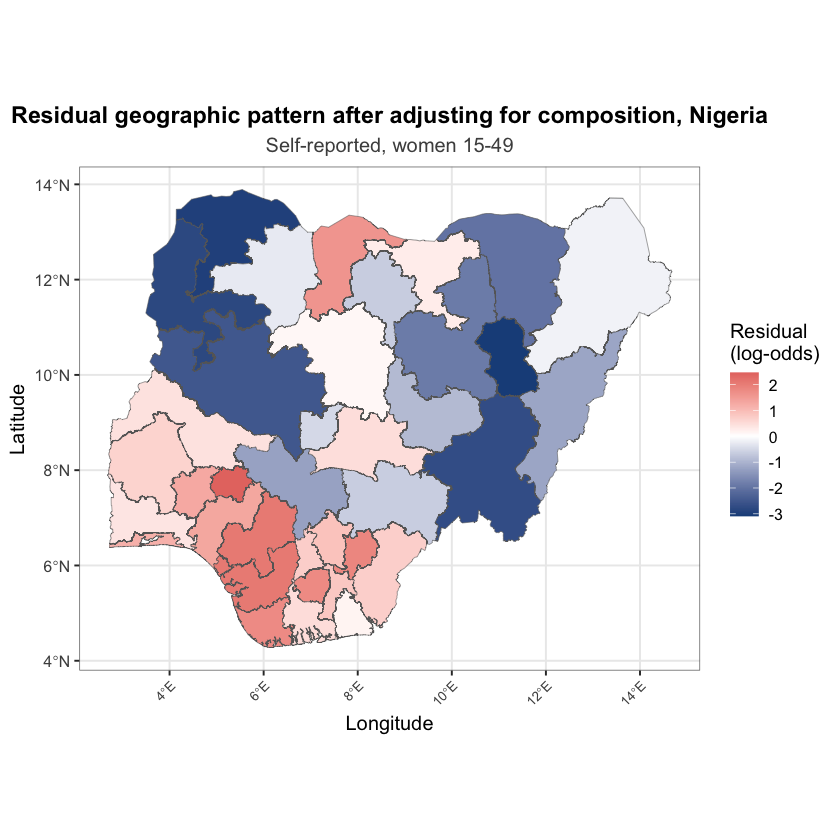

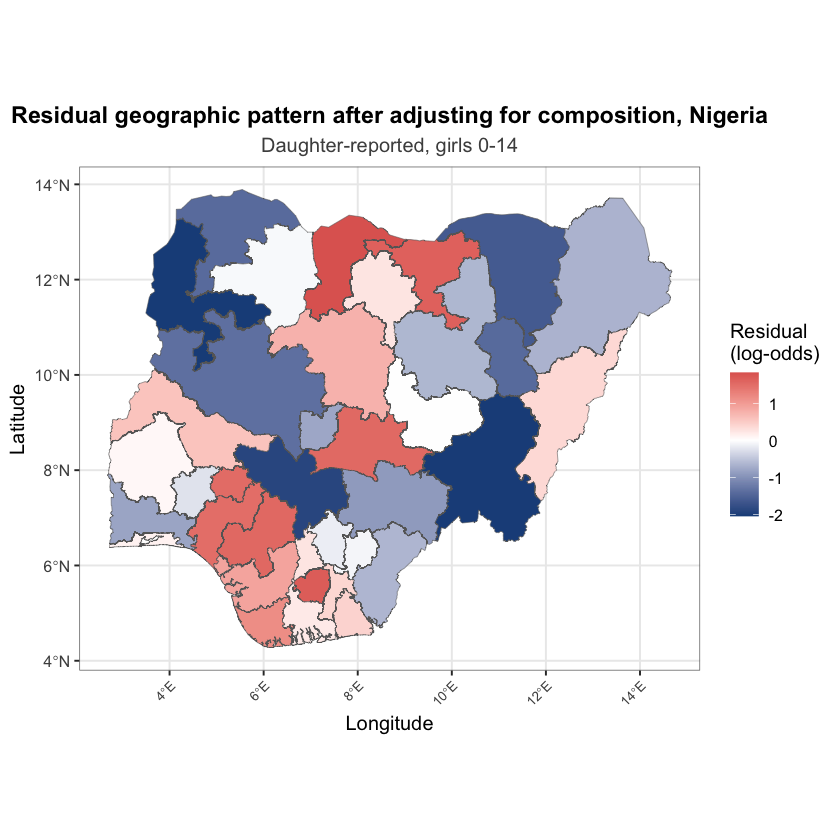

In [49]:
if (run_spatial_model) {
  extract_residual_effect <- function(model, model_data) {
    region_lookup <- model_data |>
      dplyr::distinct(region, region_id) |>
      dplyr::arrange(region_id)
    model$summary.random$region_id |>
      dplyr::filter(ID %in% region_lookup$region_id) |>
      dplyr::rename(region_id = ID, residual_effect = mean) |>
      dplyr::left_join(region_lookup, by = "region_id") |>
      dplyr::select(region, region_id, residual_effect)
  }

  residual_self     <- extract_residual_effect(covariate_model_self,     women_covariate_data)
  residual_daughter <- extract_residual_effect(covariate_model_daughter, daughters_covariate_data)

  readr::write_csv(residual_self,     file.path(output_dir, paste0(country_iso3, "_prevalence_residual_spatial_self.csv")))
  readr::write_csv(residual_daughter, file.path(output_dir, paste0(country_iso3, "_prevalence_residual_spatial_daughter.csv")))

  make_residual_map <- function(residual_estimates, subtitle_label) {
    map_data <- boundaries |>
      dplyr::mutate(.region_key = toupper(.data[[region_var_shapefile]]),
                     .region_key = dplyr::if_else(.region_key == "FCT", "FCT ABUJA", .region_key)) |>
      dplyr::left_join(residual_estimates, by = c(".region_key" = "region"))

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(ggplot2::aes(fill = residual_effect), color = "grey40", linewidth = 0.15) +
      ggplot2::scale_fill_gradient2(name = "Residual\n(log-odds)", low = "#1D4E89", mid = "white",
                                      high = "#D9534F", midpoint = 0) +
      ggplot2::labs(title = paste("Residual geographic pattern after adjusting for composition,", country_name),
                    subtitle = subtitle_label, x = "Longitude", y = "Latitude") +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8)
      )
  }

  residual_self_map     <- make_residual_map(residual_self,     "Self-reported, women 15-49")
  residual_daughter_map <- make_residual_map(residual_daughter, "Daughter-reported, girls 0-14")

  print(residual_self_map)
  print(residual_daughter_map)

  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_prevalence_residual_map_self.png")),
                   plot = residual_self_map, width = 9, height = 8, dpi = 300, bg = "white")
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_prevalence_residual_map_daughter.png")),
                   plot = residual_daughter_map, width = 9, height = 8, dpi = 300, bg = "white")
} else {
  message("Spatial model disabled for this run")
}

### 6.3 Interpretation and limitations

- Normalized DHS weights enter the INLA likelihood and the aggregation of full
  fitted probabilities. This corrects the previous unweighted analysis, but it
  remains a pseudo-likelihood: the posterior intervals do not fully reproduce
  stratification, PSU clustering, or correlation among daughters of one mother.
- `age` is included flexibly through an RW2 effect. This is essential because
  FGM prevalence is cumulative with exposure time, especially for girls 0-14.
  Separate models allow the women's and daughters' age patterns to differ.
- `region` was deliberately excluded as a fixed effect -- it is already the
  spatial random effect itself; including it twice would be redundant with,
  and would fight against, the BYM2 term.
- These estimates average predictions over the observed survey-weighted
  covariate distribution in each state. Full MRP would instead require external
  state population counts for the joint age/ethnicity/wealth/education/religion/
  urban-rural cells.
- A handful of small categories (e.g. certain minority ethnic groups) may show very
  large coefficients with very wide uncertainty bands. That is near-complete
  separation from a small sample, not a bug -- treat those specific estimates
  with real caution rather than as precise effects.

# trend analysis

=== Adjusted national averages ===
# A tibble: 2 x 2
  record_type       national_average
  <fct>                        <dbl>
1 Self-reported                0.138
2 Daughter-reported            0.143

=== Adjusted birth-cohort averages ===
# A tibble: 11 x 5
   record_type       birth_cohort adjusted_prevalence lower_ci upper_ci
   <fct>             <ord>                      <dbl>    <dbl>    <dbl>
 1 Self-reported     1975 to 1979              0.234    0.223    0.245 
 2 Self-reported     1980 to 1984              0.207    0.200    0.213 
 3 Self-reported     1985 to 1989              0.177    0.172    0.183 
 4 Self-reported     1990 to 1994              0.150    0.144    0.155 
 5 Self-reported     1995 to 1999              0.118    0.114    0.123 
 6 Self-reported     2000 to 2004              0.0937   0.0898   0.0976
 7 Self-reported     2005 to 2009              0.0772   0.0720   0.0830
 8 Daughter-reported 2005 to 2009              0.144    0.135    0.153 
 9 Daughter-reported

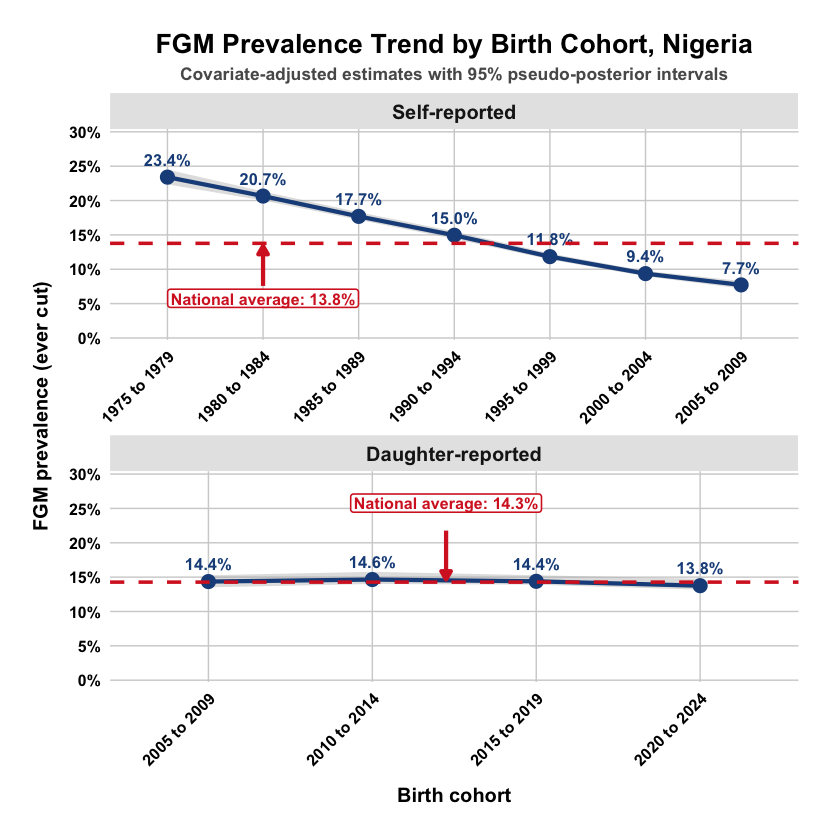

In [50]:
# ============================================================
# Prepare adjusted cohort labels and national averages
# ============================================================

adjusted_prevalence_trend_plot_data <- adjusted_prevalence_trend |>
  dplyr::mutate(
    cohort_average_label = scales::percent(
      adjusted_prevalence,
      accuracy = 0.1
    )
  )

# Calculate adjusted national averages separately.
adjusted_national_average <- adjusted_prevalence_trend |>
  dplyr::group_by(record_type) |>
  dplyr::summarise(
    national_average = stats::weighted.mean(
      adjusted_prevalence,
      w = sum_survey_weight,
      na.rm = TRUE
    ),
    .groups = "drop"
  )

# Select the second cohort as the basic annotation position.
national_average_annotations <- adjusted_prevalence_trend |>
  dplyr::arrange(
    record_type,
    birth_cohort
  ) |>
  dplyr::group_by(record_type) |>
  dplyr::mutate(
    cohort_position = dplyr::row_number()
  ) |>
  dplyr::filter(
    cohort_position == min(2L, dplyr::n())
  ) |>
  dplyr::ungroup() |>
  dplyr::select(
    record_type,
    birth_cohort
  ) |>
  dplyr::left_join(
    adjusted_national_average,
    by = "record_type"
  ) |>
  dplyr::mutate(
    national_average_label = paste0(
      "National average: ",
      scales::percent(
        national_average,
        accuracy = 0.1
      )
    ),

    # Self-reported label below the red line.
    # Daughter-reported label above the red line.
    national_label_y = dplyr::if_else(
      as.character(record_type) == "Self-reported",
      pmax(national_average - 0.08, 0.025),
      national_average + 0.115
    ),

    arrow_start_y = dplyr::if_else(
      as.character(record_type) == "Self-reported",
      national_label_y + 0.018,
      national_label_y - 0.040
    ),

    arrow_end_y = dplyr::if_else(
      as.character(record_type) == "Self-reported",
      national_average - 0.004,
      national_average + 0.004
    )
  )

# Separate the annotations so the daughter arrow can be shifted.
self_national_annotation <- national_average_annotations |>
  dplyr::filter(
    as.character(record_type) == "Self-reported"
  )

daughter_national_annotation <- national_average_annotations |>
  dplyr::filter(
    as.character(record_type) == "Daughter-reported"
  )

# Move the daughter arrow and label between the second and third cohorts.
daughter_arrow_nudge <- 0.45

# Save adjusted national averages.
readr::write_csv(
  adjusted_national_average,
  file.path(
    output_dir,
    paste0(
      country_iso3,
      "_prevalence_covariate_adjusted_national_average.csv"
    )
  )
)

# ============================================================
# Create adjusted prevalence trend plot
# ============================================================

adjusted_prevalence_trend_plot <- ggplot2::ggplot(
  adjusted_prevalence_trend_plot_data,
  ggplot2::aes(
    x = birth_cohort,
    y = adjusted_prevalence
  )
) +

  # 95% pseudo-posterior uncertainty interval
  ggplot2::geom_ribbon(
    ggplot2::aes(
      ymin = lower_ci,
      ymax = upper_ci,
      group = 1
    ),
    fill = "grey70",
    alpha = 0.40
  ) +

  # Adjusted prevalence trend
  ggplot2::geom_line(
    ggplot2::aes(group = 1),
    color = "#1D4E89",
    linewidth = 1.2
  ) +

  # Cohort prevalence points
  ggplot2::geom_point(
    color = "#1D4E89",
    fill = "#1D4E89",
    shape = 21,
    size = 3.2,
    stroke = 0.8
  ) +

  # Percentage label for every cohort
  ggplot2::geom_text(
    ggplot2::aes(
      label = cohort_average_label
    ),
    color = "#1D4E89",
    fontface = "bold",
    size = 3.5,
    vjust = -1
  ) +

  # National-average reference lines
  ggplot2::geom_hline(
    data = adjusted_national_average,
    ggplot2::aes(
      yintercept = national_average
    ),
    color = "#D62728",
    linewidth = 1,
    linetype = "dashed",
    inherit.aes = FALSE
  ) +

  # ----------------------------------------------------------
  # Self-reported annotation
  # ----------------------------------------------------------

  ggplot2::geom_segment(
    data = self_national_annotation,
    ggplot2::aes(
      x = birth_cohort,
      xend = birth_cohort,
      y = arrow_start_y,
      yend = arrow_end_y
    ),
    inherit.aes = FALSE,
    color = "#D62728",
    linewidth = 1.2,
    arrow = grid::arrow(
      type = "closed",
      length = grid::unit(
        0.20,
        "cm"
      )
    )
  ) +

  ggplot2::geom_label(
    data = self_national_annotation,
    ggplot2::aes(
      x = birth_cohort,
      y = national_label_y,
      label = national_average_label
    ),
    inherit.aes = FALSE,
    color = "#D62728",
    fill = "white",
    fontface = "bold",
    size = 3.4,
    label.size = 0.45,
    label.padding = grid::unit(
      0.16,
      "lines"
    )
  ) +

  # ----------------------------------------------------------
  # Daughter-reported annotation
  #
  # Both the label and arrow are shifted horizontally between
  # cohort points. This prevents the arrow from crossing 14.6%.
  # ----------------------------------------------------------

  ggplot2::geom_segment(
    data = daughter_national_annotation,
    ggplot2::aes(
      x = birth_cohort,
      xend = birth_cohort,
      y = arrow_start_y,
      yend = arrow_end_y
    ),
    inherit.aes = FALSE,
    position = ggplot2::position_nudge(
      x = daughter_arrow_nudge
    ),
    color = "#D62728",
    linewidth = 1.2,
    arrow = grid::arrow(
      type = "closed",
      length = grid::unit(
        0.20,
        "cm"
      )
    )
  ) +

  ggplot2::geom_label(
    data = daughter_national_annotation,
    ggplot2::aes(
      x = birth_cohort,
      y = national_label_y,
      label = national_average_label
    ),
    inherit.aes = FALSE,
    position = ggplot2::position_nudge(
      x = daughter_arrow_nudge
    ),
    color = "#D62728",
    fill = "white",
    fontface = "bold",
    size = 3.4,
    label.size = 0.45,
    label.padding = grid::unit(
      0.16,
      "lines"
    )
  ) +

  # Separate women and daughters
  ggplot2::facet_wrap(
    ~record_type,
    ncol = 1,
    scales = "free_x"
  ) +

  # Percentage scale
  ggplot2::scale_y_continuous(
    labels = scales::percent_format(
      accuracy = 1
    ),
    breaks = scales::breaks_width(0.05),
    limits = c(0, NA),
    expand = ggplot2::expansion(
      mult = c(0.01, 0.18)
    )
  ) +

  # Titles and axis labels
  ggplot2::labs(
    title = paste(
      "FGM Prevalence Trend by Birth Cohort,",
      country_name
    ),
    subtitle = paste(
      "Covariate-adjusted estimates with 95%",
      "pseudo-posterior intervals"
    ),
    x = "Birth cohort",
    y = "FGM prevalence (ever cut)"
  ) +

  ggplot2::coord_cartesian(
    clip = "off"
  ) +

  ggplot2::theme_minimal(
    base_size = 12
  ) +

  ggplot2::theme(
    text = ggplot2::element_text(
      face = "bold",
      color = "black"
    ),

    plot.title = ggplot2::element_text(
      face = "bold",
      size = 16,
      hjust = 0.5
    ),

    plot.subtitle = ggplot2::element_text(
      face = "bold",
      size = 10.5,
      hjust = 0.5,
      color = "grey35"
    ),

    axis.title.x = ggplot2::element_text(
      face = "bold",
      size = 12,
      margin = ggplot2::margin(t = 12)
    ),

    axis.title.y = ggplot2::element_text(
      face = "bold",
      size = 12,
      margin = ggplot2::margin(r = 10)
    ),

    axis.text = ggplot2::element_text(
      face = "bold",
      color = "black"
    ),

    axis.text.x = ggplot2::element_text(
      face = "bold",
      angle = 45,
      hjust = 1
    ),

    strip.text = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    strip.background = ggplot2::element_rect(
      fill = "grey90",
      color = NA
    ),

    panel.grid.major = ggplot2::element_line(
      color = "grey82",
      linewidth = 0.4
    ),

    panel.grid.minor = ggplot2::element_blank(),

    plot.margin = ggplot2::margin(
      20,
      25,
      20,
      20
    )
  )

# Display the plot.
print(adjusted_prevalence_trend_plot)

# Save the plot.
ggplot2::ggsave(
  file.path(
    output_dir,
    paste0(
      country_iso3,
      "_prevalence_trend_covariate_adjusted_annotated.png"
    )
  ),
  plot = adjusted_prevalence_trend_plot,
  width = 10,
  height = 9,
  dpi = 300,
  bg = "white"
)

# Print numerical results.
cat("=== Adjusted national averages ===\n")
print(adjusted_national_average)

cat("\n=== Adjusted birth-cohort averages ===\n")
print(
  adjusted_prevalence_trend |>
    dplyr::select(
      record_type,
      birth_cohort,
      adjusted_prevalence,
      lower_ci,
      upper_ci
    )
)

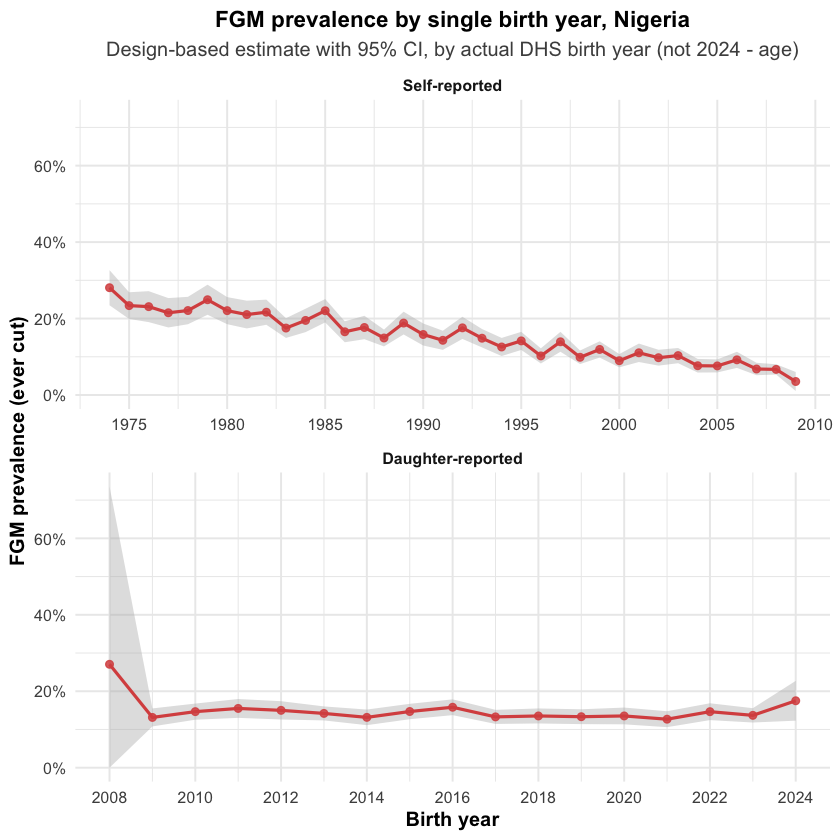

In [51]:
# Same idea at single-birth-year resolution
women_year_design    <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight,
                                            data = women |> dplyr::filter(!is.na(fgm_self)), nest = TRUE)
women_year_est <- survey::svyby(~fgm_self, ~birth_year, women_year_design, survey::svymean, na.rm = TRUE) |>
  dplyr::rename(prevalence = fgm_self) |>
  dplyr::mutate(lower_ci = pmax(prevalence - 1.96 * se, 0), upper_ci = pmin(prevalence + 1.96 * se, 1),
                record_type = "Self-reported")

daughters_year_design <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight,
                                             data = daughters |> dplyr::filter(!is.na(fgm_daughter)), nest = TRUE)
daughters_year_est <- survey::svyby(~fgm_daughter, ~birth_year, daughters_year_design, survey::svymean, na.rm = TRUE) |>
  dplyr::rename(prevalence = fgm_daughter) |>
  dplyr::mutate(lower_ci = pmax(prevalence - 1.96 * se, 0), upper_ci = pmin(prevalence + 1.96 * se, 1),
                record_type = "Daughter-reported")

prevalence_by_year <- dplyr::bind_rows(women_year_est, daughters_year_est) |>
  dplyr::mutate(record_type = factor(record_type, levels = c("Self-reported", "Daughter-reported")))

prevalence_year_plot <- ggplot2::ggplot(prevalence_by_year, ggplot2::aes(x = birth_year, y = prevalence, group = record_type)) +
  ggplot2::geom_ribbon(ggplot2::aes(ymin = lower_ci, ymax = upper_ci), fill = "grey70", alpha = 0.4) +
  ggplot2::geom_line(color = "#D9534F", linewidth = 0.9) +
  ggplot2::geom_point(color = "#D9534F", size = 1.8, alpha = 0.85) +
  ggplot2::facet_wrap(~record_type, ncol = 1, scales = "free_x") +
  ggplot2::scale_x_continuous(breaks = scales::pretty_breaks(n = 10)) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA)) +
  ggplot2::labs(
    title = paste("FGM prevalence by single birth year,", country_name),
    subtitle = "Design-based estimate with 95% CI, by actual DHS birth year (not 2024 - age)",
    x = "Birth year", y = "FGM prevalence (ever cut)"
  ) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(
    plot.title = ggplot2::element_text(face = "bold", size = 13.5, hjust = 0.5),
    plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
    axis.title = ggplot2::element_text(face = "bold"),
    strip.text = ggplot2::element_text(face = "bold")
  )

print(prevalence_year_plot)
ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_prevalence_trend_by_year.png")),
                 plot = prevalence_year_plot, width = 10, height = 8, dpi = 300, bg = "white")


In [52]:
cat("=== Validation against official DHS 2024 figures ===\n")
cat("National, women 15-49:  ", round(coef(svymean(~fgm_self, women_design)) * 100, 2), "% (target ~14%)\n")
cat("National, girls 0-14:   ", round(coef(svymean(~fgm_daughter, daughter_design)) * 100, 2), "% (target ~14%)\n")
cat("Katsina, women:          ", round(direct_self$fgm_self[direct_self$region == "KATSINA"] * 100, 1), "% (target ~50%)\n")
cat("Ekiti, women:            ", round(direct_self$fgm_self[direct_self$region == "EKITI"] * 100, 1), "% (target ~48%)\n")


=== Validation against official DHS 2024 figures ===
National, women 15-49:   13.87 % (target ~14%)
National, girls 0-14:    14.09 % (target ~14%)
Katsina, women:           49.7 % (target ~50%)
Ekiti, women:             47.9 % (target ~48%)


## Notes

- Outcome definition: simple cumulative "ever cut" prevalence (matching SDG
  indicator 5.3.2), not the discrete-time hazard framing `FGM_Risk_
  Incidence.ipynb` uses -- these are two different, complementary
  statistics, not the same measure at two resolutions.
- `multilevel_EM` was deliberately not attempted here; see the top of this
  notebook and `FGM_Attitudinal_Incidence_v2.ipynb` Section 8B for the full,
  reproducible evidence of why.
- Same shared color scale across the self- and daughter-reported maps, so
  they can be visually compared directly.
- All outputs saved under `03_Outputs/FGM_Prevalence/`, kept separate from
  the risk-incidence and attitude-incidence outputs in `03_Outputs/NGA/`.